In [1]:

# ==========================================
# 1. Environment Setup
# ==========================================

import os
import json
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter, defaultdict

from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

print("Environment initialized successfully.")


Mounted at /content/drive
Environment initialized successfully.



# 02 — Data Exploration & Statistical Analysis

## Image Captioning Project — MS COCO 2017

### 1. Introduction

This notebook performs data exploration and statistical analysis
of the selected MS COCO 2017 dataset.

The analysis focuses on object distributions, object counts per
image, caption characteristics, vocabulary, and scene complexity.

### 2. Dataset Configuration

| Component | Dataset Source | Number of Images |
|---|---|---:|
| Training | train2017 | 10,000 |
| Validation | train2017 | 100 |
| Total | train2017 | 10,100 |
| Test | val2017 | 1,000 |

The validation images are selected independently from the
training images. The test dataset is kept separate.

### 3. Analysis Objectives

- Explore extracted objects and their distribution.
- Analyze the number of objects per image.
- Compare data before and after preprocessing.
- Analyze caption length and vocabulary.
- Examine linguistic and descriptive characteristics.
- Generate statistical summaries and visualizations.

### 4. Methodology

Object statistics are based on the object data obtained during
the previous project steps. When available, extracted objects
are linked to their corresponding images.

COCO instance annotations may also be used as reference data
for comparison.

Caption-based statistics are supplementary analyses using
the human-generated COCO captions.


In [2]:

# ==========================================
# 2. Load COCO Dataset
# ==========================================

# Define project paths
BASE_DIR = "/content/drive/MyDrive/COCO_Project"

ANNOTATIONS_DIR = os.path.join(BASE_DIR, "annotations")
METADATA_DIR = os.path.join(BASE_DIR, "metadata")
STATISTICS_DIR = os.path.join(BASE_DIR, "statistics")

# Create statistics directory if it does not exist
os.makedirs(STATISTICS_DIR, exist_ok=True)

# Define annotation file paths
instances_path = os.path.join(
    ANNOTATIONS_DIR,
    "instances_train2017.json"
)

captions_path = os.path.join(
    ANNOTATIONS_DIR,
    "captions_train2017.json"
)

# Verify that files exist
assert os.path.exists(instances_path), "Instances file not found!"
assert os.path.exists(captions_path), "Captions file not found!"

# Load annotations
with open(instances_path, "r", encoding="utf-8") as f:
    instances = json.load(f)

with open(captions_path, "r", encoding="utf-8") as f:
    captions = json.load(f)

print("COCO annotation files loaded successfully!")
print("Statistics directory:", STATISTICS_DIR)


COCO annotation files loaded successfully!
Statistics directory: /content/drive/MyDrive/COCO_Project/statistics


In [4]:

# ==========================================
# 3. Load Selected Image IDs
# ==========================================

# Load the selected image IDs from Person 1
selected_ids_path = os.path.join(
    METADATA_DIR,
    "selected_image_ids.csv"
)

# Verify that the CSV file exists
assert os.path.exists(selected_ids_path), \
    "Selected image IDs file not found!"

# Load the CSV file
selected_ids_df = pd.read_csv(selected_ids_path)

# Verify that the required column exists
assert "image_id" in selected_ids_df.columns, \
    "The CSV must contain an 'image_id' column!"

# Remove missing image IDs
selected_ids_df = selected_ids_df.dropna(subset=["image_id"])

# Convert image IDs to integers
selected_ids_df["image_id"] = selected_ids_df["image_id"].astype(int)

# Check for duplicate image IDs
duplicate_count = selected_ids_df["image_id"].duplicated().sum()

print("Selected image IDs loaded successfully!")

# Display the first rows
display(selected_ids_df.head())

# Display dataset information
print("\nCSV columns:")
print(selected_ids_df.columns.tolist())

print("\nTotal selected records:", len(selected_ids_df))

print("Unique image IDs:", selected_ids_df["image_id"].nunique())

print("Duplicate image IDs:", duplicate_count)
# Check image distribution across splits
print("\nImage distribution by split:")
print(selected_ids_df["split"].value_counts())

# Check for missing values
print("\nMissing values:")
print(selected_ids_df.isnull().sum())

# Check file naming consistency
print("\nFile names matching image IDs:")
print(
    (selected_ids_df["file_name"] ==
     selected_ids_df["image_id"].apply(lambda x: f"{x:012d}.jpg")).all()
)

Selected image IDs loaded successfully!


,image_id,split,file_name
0,411685,knowledge_base,000000411685.jpg
1,71573,knowledge_base,000000071573.jpg
2,16285,knowledge_base,000000016285.jpg
3,478093,knowledge_base,000000478093.jpg
4,177361,knowledge_base,000000177361.jpg



CSV columns:
['image_id', 'split', 'file_name']

Total selected records: 10100
Unique image IDs: 10100
Duplicate image IDs: 0

Image distribution by split:
split
knowledge_base    10000
validation          100
Name: count, dtype: int64

Missing values:
image_id     0
split        0
file_name    0
dtype: int64

File names matching image IDs:
True


In [5]:

# ==========================================
# 4. Separate Dataset Splits
# ==========================================

# Extract image IDs for each split
knowledge_base_ids = set(
    selected_ids_df[
        selected_ids_df["split"] == "knowledge_base"
    ]["image_id"]
)

validation_ids = set(
    selected_ids_df[
        selected_ids_df["split"] == "validation"
    ]["image_id"]
)

# Combine all selected image IDs
selected_all_ids = knowledge_base_ids.union(validation_ids)

# Verify dataset sizes
print("DATASET SPLIT VERIFICATION")
print("--------------------------")
print("Knowledge Base images:", len(knowledge_base_ids))
print("Validation images:", len(validation_ids))
print("Total selected images:", len(selected_all_ids))

# Check for overlap
overlap = knowledge_base_ids.intersection(validation_ids)

print("Overlapping image IDs:", len(overlap))

# Verify dataset requirements
assert len(knowledge_base_ids) == 10000, \
    "Training dataset must contain 10,000 images!"

assert len(validation_ids) == 100, \
    "Validation dataset must contain 100 images!"

assert len(selected_all_ids) == 10100, \
    "Total selected images must be 10,100!"

assert len(overlap) == 0, \
    "Training and validation datasets must not overlap!"

print("\nAll dataset split checks passed successfully!")


DATASET SPLIT VERIFICATION
--------------------------
Knowledge Base images: 10000
Validation images: 100
Total selected images: 10100
Overlapping image IDs: 0

All dataset split checks passed successfully!


In [6]:

# ==========================================
# 5. Filter Annotations
# ==========================================

# Filter COCO object annotations
selected_instances = [
    ann for ann in instances["annotations"]
    if ann["image_id"] in selected_all_ids
]

# Filter COCO caption annotations
selected_captions = [
    ann for ann in captions["annotations"]
    if ann["image_id"] in selected_all_ids
]

# Extract category names
category_names = {
    category["id"]: category["name"]
    for category in instances["categories"]
}

# Verify selected images exist in COCO metadata
instance_image_ids = {
    image["id"] for image in instances["images"]
}

caption_image_ids = {
    image["id"] for image in captions["images"]
}

missing_instance_images = selected_all_ids - instance_image_ids
missing_caption_images = selected_all_ids - caption_image_ids

# Display results
print("ANNOTATION FILTERING RESULTS")
print("----------------------------")
print("Selected images:", len(selected_all_ids))
print("Object annotations:", len(selected_instances))
print("Caption annotations:", len(selected_captions))
print("Object categories:", len(category_names))

print("\nIMAGE VERIFICATION")
print("------------------")
print("Images missing from instances:", len(missing_instance_images))
print("Images missing from captions:", len(missing_caption_images))

# Verify annotation consistency
assert len(missing_instance_images) == 0, \
    "Some selected images are missing from instances annotations!"

assert len(missing_caption_images) == 0, \
    "Some selected images are missing from captions annotations!"

print("\nAll annotation checks passed successfully!")


ANNOTATION FILTERING RESULTS
----------------------------
Selected images: 10100
Object annotations: 72752
Caption annotations: 50521
Object categories: 80

IMAGE VERIFICATION
------------------
Images missing from instances: 0
Images missing from captions: 0

All annotation checks passed successfully!


In [7]:

# ==========================================
# 6. Object Category Distribution
# ==========================================

# Count COCO annotations for each category
category_counts = Counter(
    ann["category_id"]
    for ann in selected_instances
)

# Create a DataFrame
category_df = pd.DataFrame([
    {
        "category_id": category_id,
        "category": category_names[category_id],
        "object_count": category_counts.get(category_id, 0)
    }
    for category_id in category_names
])

# Calculate category percentages
total_objects = category_df["object_count"].sum()

category_df["percentage"] = (
    category_df["object_count"] / total_objects * 100
).round(2)

# Sort categories by frequency
category_df = category_df.sort_values(
    by="object_count",
    ascending=False
).reset_index(drop=True)

# Display the most frequent categories
print("TOP 10 MOST FREQUENT COCO OBJECT CATEGORIES")
display(category_df.head(10))

# Display basic statistics
print("\nCategory statistics:")
print("Total categories:", len(category_df))
print("Categories with annotations:",
      (category_df["object_count"] > 0).sum())
print("Total object annotations:", total_objects)
print("Average annotations per category:",
      round(category_df["object_count"].mean(), 2))

# Verify annotation count
assert total_objects == len(selected_instances), \
    "Category counts do not match the total annotations!"

print("\nCategory distribution verified successfully!")


TOP 10 MOST FREQUENT COCO OBJECT CATEGORIES


,category_id,category,object_count,percentage
0,1,person,22319,30.68
1,3,car,3664,5.04
2,62,chair,3207,4.41
3,44,bottle,2064,2.84
4,84,book,2009,2.76
5,47,cup,1672,2.30
6,67,dining table,1287,1.77
7,51,bowl,1235,1.70
8,28,umbrella,1097,1.51
9,31,handbag,1031,1.42



Category statistics:
Total categories: 80
Categories with annotations: 80
Total object annotations: 72752
Average annotations per category: 909.4

Category distribution verified successfully!


In [8]:

# ==========================================
# 7. Save Object Category Statistics
# ==========================================

# Save the complete category distribution
category_csv_path = os.path.join(
    STATISTICS_DIR,
    "object_category_distribution.csv"
)

category_df.to_csv(
    category_csv_path,
    index=False,
    encoding="utf-8"
)

# Verify that the file was saved
assert os.path.exists(category_csv_path), \
    "Category statistics file was not saved!"

print("Category statistics saved successfully!")
print("File:", category_csv_path)
print("Saved records:", len(category_df))


Category statistics saved successfully!
File: /content/drive/MyDrive/COCO_Project/statistics/object_category_distribution.csv
Saved records: 80


In [9]:

# ==========================================
# 9. Verify Project Directories
# ==========================================

# Verify project directories
print("PROJECT DIRECTORY VERIFICATION")
print("--------------------------------")

print("Project directory:", os.path.exists(BASE_DIR))
print("Annotations directory:", os.path.exists(ANNOTATIONS_DIR))
print("Metadata directory:", os.path.exists(METADATA_DIR))
print("Statistics directory:", os.path.exists(STATISTICS_DIR))

# Verify all required directories
assert os.path.exists(BASE_DIR), "Project directory not found!"
assert os.path.exists(ANNOTATIONS_DIR), "Annotations directory not found!"
assert os.path.exists(METADATA_DIR), "Metadata directory not found!"
assert os.path.exists(STATISTICS_DIR), "Statistics directory not found!"

print("\nAll project directories verified successfully!")


PROJECT DIRECTORY VERIFICATION
--------------------------------
Project directory: True
Annotations directory: True
Metadata directory: True
Statistics directory: True

All project directories verified successfully!


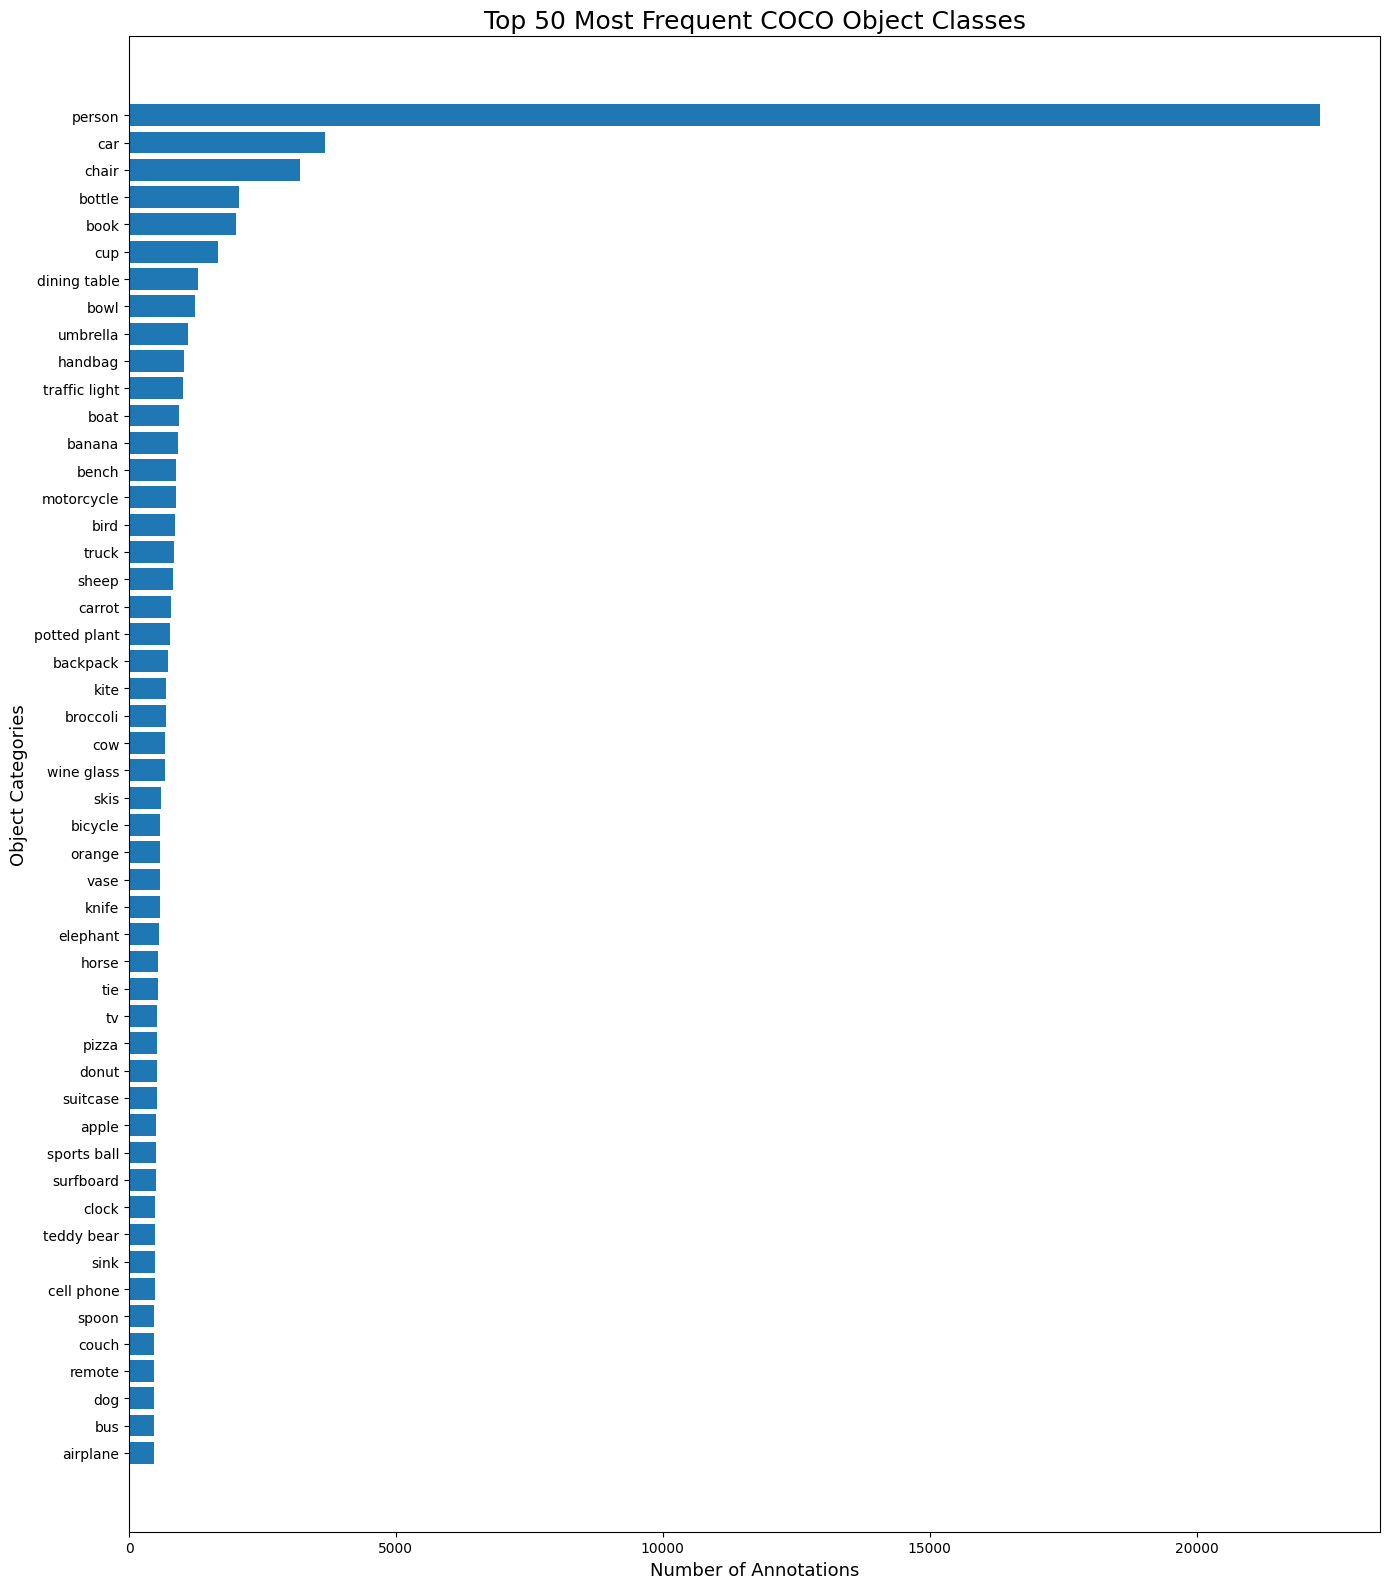

Top 50 visualization saved successfully!
Number of categories displayed: 50
Saved at: /content/drive/MyDrive/COCO_Project/statistics/top_50_object_classes.png


In [10]:

# ==========================================
# 8. Top 50 Object Classes Distribution
# ==========================================

# Select the 50 most frequent object categories
top_50_categories = category_df.head(50).sort_values(
    by="object_count",
    ascending=True
)

# Create horizontal bar chart
plt.figure(figsize=(14, 16))

plt.barh(
    top_50_categories["category"],
    top_50_categories["object_count"]
)

plt.title(
    "Top 50 Most Frequent COCO Object Classes",
    fontsize=18
)

plt.xlabel("Number of Annotations", fontsize=13)
plt.ylabel("Object Categories", fontsize=13)

plt.tight_layout()

# Save visualization in Google Drive
graph_path = os.path.join(
    STATISTICS_DIR,
    "top_50_object_classes.png"
)

plt.savefig(
    graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Display results
print("Top 50 visualization saved successfully!")
print("Number of categories displayed:", len(top_50_categories))
print("Saved at:", graph_path)


In [11]:

# ==========================================
# 9. Most and Least Frequent Object Categories
# ==========================================

# Identify the most and least frequent categories
most_frequent = category_df.loc[
    category_df["object_count"].idxmax()
]

least_frequent = category_df.loc[
    category_df["object_count"].idxmin()
]

print("MOST AND LEAST FREQUENT OBJECT CATEGORIES")
print("------------------------------------------")

print("\nMost frequent category:")
print("Category:", most_frequent["category"])
print("Number of objects:", most_frequent["object_count"])

print("\nLeast frequent category:")
print("Category:", least_frequent["category"])
print("Number of objects:", least_frequent["object_count"])

# Calculate the frequency difference
frequency_difference = (
    most_frequent["object_count"] -
    least_frequent["object_count"]
)

print("\nFrequency difference:", int(frequency_difference))


MOST AND LEAST FREQUENT OBJECT CATEGORIES
------------------------------------------

Most frequent category:
Category: person
Number of objects: 22319

Least frequent category:
Category: hair drier
Number of objects: 18

Frequency difference: 22301


In [12]:

# ==========================================
# 10. Save Most and Least Frequent Categories
# ==========================================

# Create a DataFrame containing the two extreme categories
extreme_categories_df = pd.DataFrame([
    {
        "frequency_type": "Most frequent",
        "category": most_frequent["category"],
        "object_count": most_frequent["object_count"]
    },
    {
        "frequency_type": "Least frequent",
        "category": least_frequent["category"],
        "object_count": least_frequent["object_count"]
    }
])

# Define the output file path
extremes_path = os.path.join(
    STATISTICS_DIR,
    "most_least_frequent_categories.csv"
)

# Save the results
extreme_categories_df.to_csv(
    extremes_path,
    index=False,
    encoding="utf-8"
)

# Verify that the file was saved
assert os.path.exists(extremes_path), \
    "The results file was not saved!"

print("Results saved successfully!")
print("File:", extremes_path)

display(extreme_categories_df)


Results saved successfully!
File: /content/drive/MyDrive/COCO_Project/statistics/most_least_frequent_categories.csv


,frequency_type,category,object_count
0,Most frequent,person,22319
1,Least frequent,hair drier,18


In [13]:

# ==========================================
# 11. Number of Objects Per Image
# ==========================================

# Count object annotations for each image
objects_per_image = Counter(
    ann["image_id"]
    for ann in selected_instances
)

# Include all selected images, even those with zero objects
image_object_counts = pd.DataFrame({
    "image_id": list(selected_all_ids)
})

image_object_counts["object_count"] = (
    image_object_counts["image_id"]
    .map(objects_per_image)
    .fillna(0)
    .astype(int)
)

# Display first rows
print("OBJECTS PER IMAGE")
display(image_object_counts.head(10))

# Calculate summary statistics
print("\nOBJECT COUNT SUMMARY")
print("--------------------")
print("Total images analyzed:", len(image_object_counts))
print("Total object annotations:",
      image_object_counts["object_count"].sum())
print("Average objects per image:",
      round(image_object_counts["object_count"].mean(), 2))
print("Maximum objects in one image:",
      image_object_counts["object_count"].max())
print("Minimum objects in one image:",
      image_object_counts["object_count"].min())
print("Images with zero objects:",
      (image_object_counts["object_count"] == 0).sum())

# Verify the results
assert len(image_object_counts) == len(selected_all_ids)
assert image_object_counts["object_count"].sum() == len(selected_instances)

print("\nObject counts verified successfully!")


OBJECTS PER IMAGE


,image_id,object_count
0,458756,9
1,393224,6
2,131084,2
3,294925,7
4,98322,7
5,294937,3
6,393241,18
7,393243,3
8,294942,26
9,524325,21



OBJECT COUNT SUMMARY
--------------------
Total images analyzed: 10100
Total object annotations: 72752
Average objects per image: 7.2
Maximum objects in one image: 56
Minimum objects in one image: 0
Images with zero objects: 104

Object counts verified successfully!


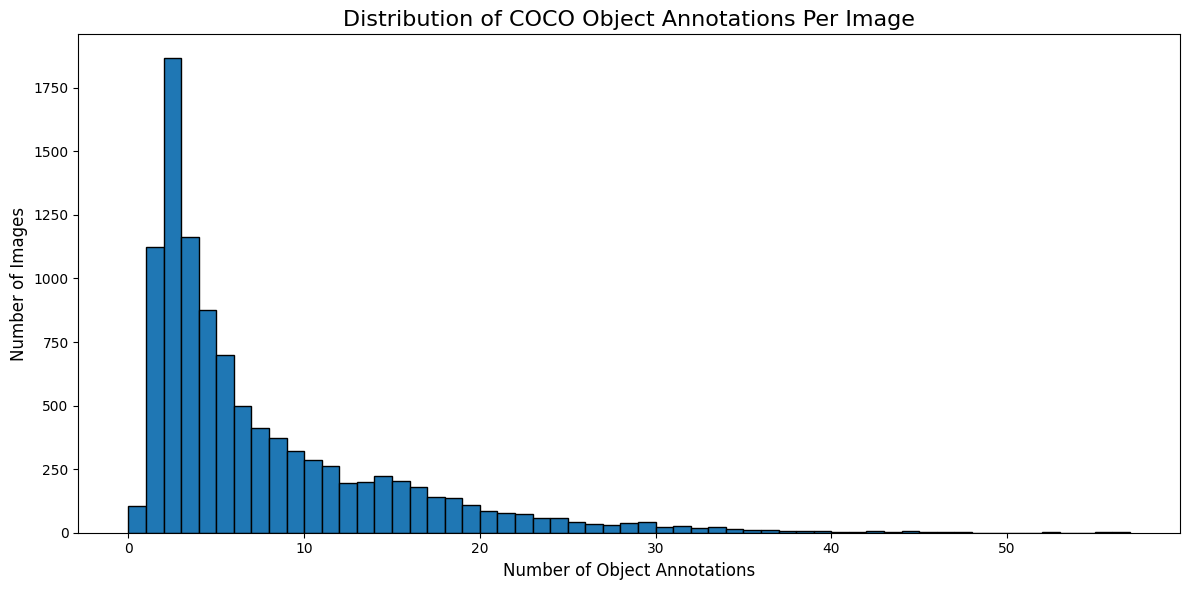

Histogram saved successfully!
File: /content/drive/MyDrive/COCO_Project/statistics/objects_per_image_distribution.png


In [14]:

# ==========================================
# 12. Distribution of Objects Per Image
# ==========================================

plt.figure(figsize=(12, 6))

plt.hist(
    image_object_counts["object_count"],
    bins=range(
        0,
        image_object_counts["object_count"].max() + 2
    ),
    edgecolor="black"
)

plt.title(
    "Distribution of COCO Object Annotations Per Image",
    fontsize=16
)

plt.xlabel("Number of Object Annotations", fontsize=12)
plt.ylabel("Number of Images", fontsize=12)

plt.tight_layout()

# Save visualization
graph_path = os.path.join(
    STATISTICS_DIR,
    "objects_per_image_distribution.png"
)

plt.savefig(
    graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Histogram saved successfully!")
print("File:", graph_path)


In [15]:

# ==========================================
# 13. Save Objects Per Image Statistics
# ==========================================

# Calculate object count statistics
average_objects = image_object_counts["object_count"].mean()
minimum_objects = image_object_counts["object_count"].min()
maximum_objects = image_object_counts["object_count"].max()

zero_object_images = (
    image_object_counts["object_count"] == 0
).sum()

# Create statistics DataFrame
object_statistics = pd.DataFrame([{
    "total_images": len(image_object_counts),
    "average_objects_per_image": round(average_objects, 2),
    "minimum_objects": minimum_objects,
    "maximum_objects": maximum_objects,
    "images_with_zero_objects": zero_object_images
}])

# Define output file path
statistics_path = os.path.join(
    STATISTICS_DIR,
    "objects_per_image_statistics.csv"
)

# Save statistics
object_statistics.to_csv(
    statistics_path,
    index=False,
    encoding="utf-8"
)

# Verify saved file
assert os.path.exists(statistics_path), \
    "Statistics file was not saved!"

print("Statistics saved successfully!")
print("File:", statistics_path)

display(object_statistics)


Statistics saved successfully!
File: /content/drive/MyDrive/COCO_Project/statistics/objects_per_image_statistics.csv


,total_images,average_objects_per_image,minimum_objects,maximum_objects,images_with_zero_objects
0,10100,7.2,0,56,104


In [16]:

# ==========================================
# 14. Caption Length Analysis
# ==========================================

# Extract caption text
caption_texts = [
    ann["caption"]
    for ann in selected_captions
    if ann.get("caption", "").strip()
]

# Calculate the number of words in each caption
caption_lengths = [
    len(caption.split())
    for caption in caption_texts
]

# Create a DataFrame
caption_df = pd.DataFrame({
    "caption": caption_texts,
    "word_count": caption_lengths
})

print("CAPTION DATA")
print("------------")
print("Total captions:", len(caption_df))
print("Average caption length:",
      round(caption_df["word_count"].mean(), 2))
print("Shortest caption:",
      caption_df["word_count"].min(), "words")
print("Longest caption:",
      caption_df["word_count"].max(), "words")

# Verify the data
assert len(caption_df) > 0, "No captions were found!"
assert (caption_df["word_count"] > 0).all(), \
    "Some captions have zero words!"

display(caption_df.head(10))


CAPTION DATA
------------
Total captions: 50521
Average caption length: 10.46
Shortest caption: 6 words
Longest caption: 47 words


,caption,word_count
0,"A bathroom with a toilet, sink, and shower.",8
1,A black cat is inside a white toilet.,8
2,A brown and black horse in the middle of the c...,13
3,four urinals in a public restroom with a window,9
4,A black cat drinking water from a toilet,8
5,A bathroom with four urinals on the wall.,8
6,A cat drinking water from a toilet in a bathroom.,10
7,An old bathroom with a row of urinals.,8
8,A full bathroom with a wicker laundry basket.,8
9,A row of urinals in with an open window above ...,11


In [17]:

# ==========================================
# 15. Caption Length Statistics
# ==========================================

# Calculate caption length statistics
average_length = caption_df["word_count"].mean()
minimum_length = caption_df["word_count"].min()
maximum_length = caption_df["word_count"].max()
median_length = caption_df["word_count"].median()
std_length = caption_df["word_count"].std()

print("CAPTION LENGTH STATISTICS")
print("-------------------------")
print(f"Median caption length: {median_length:.2f} words")
print(f"Standard deviation: {std_length:.2f} words")

print("\nInterpretation:")
print(
    "The median represents the middle caption length, "
    "while the standard deviation shows how much caption "
    "lengths vary around the average."
)


CAPTION LENGTH STATISTICS
-------------------------
Median caption length: 10.00 words
Standard deviation: 2.40 words

Interpretation:
The median represents the middle caption length, while the standard deviation shows how much caption lengths vary around the average.


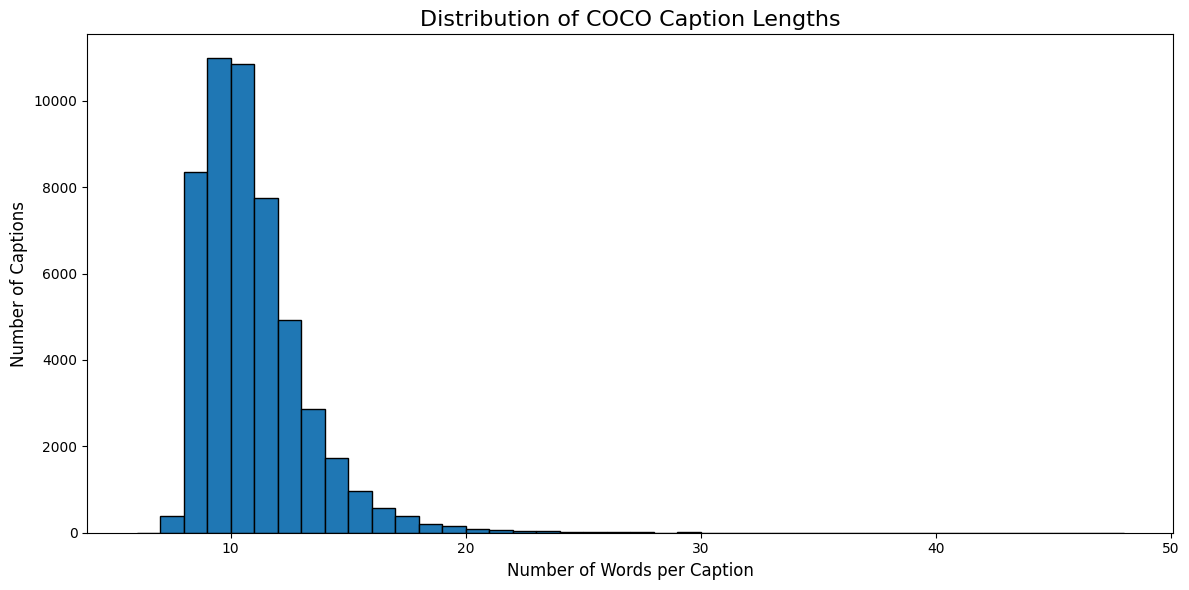

Caption length histogram saved successfully!
File: /content/drive/MyDrive/COCO_Project/statistics/caption_length_distribution.png


In [18]:

# ==========================================
# 16. Caption Length Distribution
# ==========================================

plt.figure(figsize=(12, 6))

plt.hist(
    caption_df["word_count"],
    bins=range(
        caption_df["word_count"].min(),
        caption_df["word_count"].max() + 2
    ),
    edgecolor="black"
)

plt.title(
    "Distribution of COCO Caption Lengths",
    fontsize=16
)

plt.xlabel("Number of Words per Caption", fontsize=12)
plt.ylabel("Number of Captions", fontsize=12)

plt.tight_layout()

# Save visualization
graph_path = os.path.join(
    STATISTICS_DIR,
    "caption_length_distribution.png"
)

plt.savefig(
    graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Caption length histogram saved successfully!")
print("File:", graph_path)


In [19]:

# ==========================================
# 17. Save Caption Length Statistics
# ==========================================

caption_statistics = pd.DataFrame([{
    "total_captions": len(caption_df),
    "average_length": round(average_length, 2),
    "minimum_length": minimum_length,
    "maximum_length": maximum_length,
    "median_length": median_length,
    "standard_deviation": round(std_length, 2)
}])

caption_stats_path = os.path.join(
    STATISTICS_DIR,
    "caption_length_statistics.csv"
)

caption_statistics.to_csv(
    caption_stats_path,
    index=False,
    encoding="utf-8"
)

assert os.path.exists(caption_stats_path), "CSV file was not saved!"

print("Caption statistics saved successfully!")
print("File:", caption_stats_path)

display(caption_statistics)


Caption statistics saved successfully!
File: /content/drive/MyDrive/COCO_Project/statistics/caption_length_statistics.csv


,total_captions,average_length,minimum_length,maximum_length,median_length,standard_deviation
0,50521,10.46,6,47,10.0,2.4


In [20]:

# ==========================================
# 18. Vocabulary Frequency Analysis
# ==========================================

# Extract and normalize words
all_words = []

for caption in caption_texts:
    if isinstance(caption, str) and caption.strip():
        words = re.findall(r"\b[a-zA-Z]+\b", caption.lower())
        all_words.extend(words)

# Count word frequencies
word_frequencies = Counter(all_words)

# Create a DataFrame
vocabulary_df = pd.DataFrame(
    word_frequencies.most_common(50),
    columns=["word", "frequency"]
)

print("VOCABULARY ANALYSIS")
print("-------------------")
print("Total words:", len(all_words))
print("Unique words:", len(word_frequencies))
print("\nTop 50 most frequent words:")

display(vocabulary_df)

# Save vocabulary statistics
vocabulary_path = os.path.join(
    STATISTICS_DIR,
    "top_50_vocabulary.csv"
)

vocabulary_df.to_csv(
    vocabulary_path,
    index=False,
    encoding="utf-8"
)

assert os.path.exists(vocabulary_path), "Vocabulary file was not saved!"

print("\nVocabulary statistics saved successfully!")
print("File:", vocabulary_path)


VOCABULARY ANALYSIS
-------------------
Total words: 529611
Unique words: 9709

Top 50 most frequent words:


,word,frequency
0,a,83696
1,on,18352
2,of,17228
3,the,16636
4,in,15903
5,with,13213
6,and,12148
7,is,8311
8,man,6329
9,to,5884



Vocabulary statistics saved successfully!
File: /content/drive/MyDrive/COCO_Project/statistics/top_50_vocabulary.csv


In [21]:

# ==========================================
# 19. Vocabulary Analysis Without Stop Words
# ==========================================

# Common English stop words
stop_words = {
    "a", "an", "the", "is", "are", "was", "were",
    "be", "been", "being", "and", "or", "but",
    "of", "in", "on", "at", "to", "for", "with",
    "by", "from", "as", "into", "onto", "up",
    "down", "over", "under", "near", "after",
    "before", "while", "that", "this", "it",
    "its", "his", "her", "their", "they", "he",
    "she", "we", "you", "i", "me", "my",
    "your", "some", "there", "here"
}

# Remove stop words
filtered_word_frequencies = Counter({
    word: count
    for word, count in word_frequencies.items()
    if word not in stop_words
})

# Create DataFrame
filtered_vocabulary_df = pd.DataFrame(
    filtered_word_frequencies.most_common(50),
    columns=["word", "frequency"]
)

print("VOCABULARY AFTER STOP-WORD REMOVAL")
print("----------------------------------")
print("Original unique words:", len(word_frequencies))
print("Remaining unique words:", len(filtered_word_frequencies))
print("\nTop 50 descriptive words:")

display(filtered_vocabulary_df)

# Save filtered vocabulary
filtered_vocabulary_path = os.path.join(
    STATISTICS_DIR,
    "top_50_vocabulary_without_stop_words.csv"
)

filtered_vocabulary_df.to_csv(
    filtered_vocabulary_path,
    index=False,
    encoding="utf-8"
)

assert os.path.exists(filtered_vocabulary_path), "Filtered vocabulary file was not saved!"

print("\nFiltered vocabulary saved successfully!")
print("File:", filtered_vocabulary_path)


VOCABULARY AFTER STOP-WORD REMOVAL
----------------------------------
Original unique words: 9709
Remaining unique words: 9657

Top 50 descriptive words:


,word,frequency
0,man,6329
1,sitting,4542
2,two,4250
3,standing,3763
4,people,3606
5,next,3271
6,white,3093
7,woman,3076
8,street,2562
9,table,2554



Filtered vocabulary saved successfully!
File: /content/drive/MyDrive/COCO_Project/statistics/top_50_vocabulary_without_stop_words.csv


In [22]:

# ==========================================
# 21. Install and Import NLP Library
# ==========================================

!pip install -q nltk

import nltk

# Download required NLTK resources
nltk.download('averaged_perceptron_tagger_eng', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

print("NLTK installed and initialized successfully!")
print("NLTK version:", nltk.__version__)


NLTK installed and initialized successfully!
NLTK version: 3.9.1


In [23]:

# ==========================================
# 22. Part-of-Speech (POS) Distribution
# ==========================================

from nltk.tokenize import word_tokenize
from nltk import pos_tag
from collections import Counter

pos_counts = Counter()

# Analyze all original captions
for caption in caption_texts:

    if not isinstance(caption, str) or not caption.strip():
        continue

    tokens = word_tokenize(caption.lower())
    tagged_words = pos_tag(tokens)

    for word, tag in tagged_words:
        if tag.startswith("NN"):
            pos_counts["Nouns"] += 1
        elif tag.startswith("VB"):
            pos_counts["Verbs"] += 1
        elif tag.startswith("JJ"):
            pos_counts["Adjectives"] += 1
        elif tag.startswith("RB"):
            pos_counts["Adverbs"] += 1
        else:
            pos_counts["Other"] += 1

# Create a DataFrame
pos_df = pd.DataFrame(
    pos_counts.items(),
    columns=["POS Category", "Frequency"]
)

pos_df["Percentage"] = (
    pos_df["Frequency"] / pos_df["Frequency"].sum()
) * 100

pos_df = pos_df.sort_values(
    by="Frequency",
    ascending=False
).reset_index(drop=True)

print("PART-OF-SPEECH DISTRIBUTION")
print("--------------------------")
print("Total tagged tokens:", pos_df["Frequency"].sum())

display(pos_df)

# Save POS statistics
pos_path = os.path.join(
    STATISTICS_DIR,
    "pos_distribution.csv"
)

pos_df.to_csv(
    pos_path,
    index=False,
    encoding="utf-8"
)

assert os.path.exists(pos_path), "POS statistics were not saved!"

print("\nPOS statistics saved successfully!")
print("File:", pos_path)


PART-OF-SPEECH DISTRIBUTION
--------------------------
Total tagged tokens: 571635


,POS Category,Frequency,Percentage
0,Other,276027,48.287281
1,Nouns,187052,32.722279
2,Verbs,61249,10.714704
3,Adjectives,43692,7.643339
4,Adverbs,3615,0.632397



POS statistics saved successfully!
File: /content/drive/MyDrive/COCO_Project/statistics/pos_distribution.csv


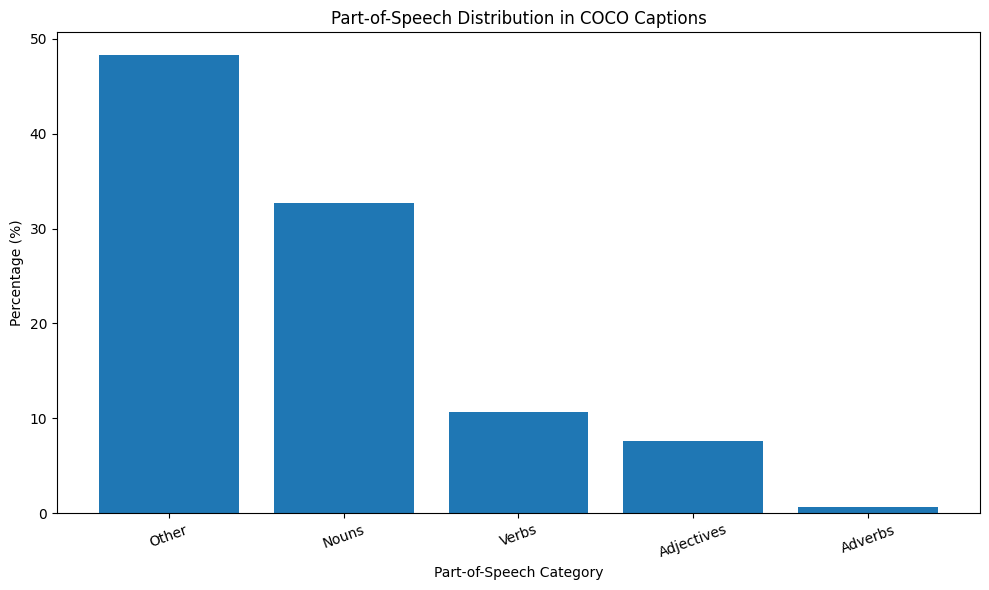

POS visualization saved successfully!
File: /content/drive/MyDrive/COCO_Project/statistics/pos_distribution.png


In [24]:

# ==========================================
# 24. POS Distribution Visualization
# ==========================================

plt.figure(figsize=(10, 6))

plt.bar(
    pos_df["POS Category"],
    pos_df["Percentage"]
)

plt.title("Part-of-Speech Distribution in COCO Captions")
plt.xlabel("Part-of-Speech Category")
plt.ylabel("Percentage (%)")

plt.xticks(rotation=20)
plt.tight_layout()

# Save visualization
pos_graph_path = os.path.join(
    STATISTICS_DIR,
    "pos_distribution.png"
)

plt.savefig(
    pos_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

assert os.path.exists(pos_graph_path), "POS visualization was not saved!"

print("POS visualization saved successfully!")
print("File:", pos_graph_path)


In [25]:

# ==========================================
# 25. Color Attribute Analysis
# ==========================================

color_words = {
    "red", "blue", "green", "yellow", "black",
    "white", "orange", "pink", "purple", "brown",
    "gray", "grey"
}

color_counts = Counter()

for caption in caption_texts:

    if not isinstance(caption, str) or not caption.strip():
        continue

    words = re.findall(r"\b[a-zA-Z]+\b", caption.lower())

    for word in words:
        if word in color_words:
            color_counts[word] += 1

# Create DataFrame
color_df = pd.DataFrame(
    color_counts.most_common(),
    columns=["Color", "Frequency"]
)

# Calculate percentages
total_color_mentions = color_df["Frequency"].sum()

color_df["Percentage"] = (
    color_df["Frequency"] / total_color_mentions
) * 100

print("COLOR ATTRIBUTE DISTRIBUTION")
print("-----------------------------")
print("Total color mentions:", total_color_mentions)

display(color_df)

# Save results
color_path = os.path.join(
    STATISTICS_DIR,
    "color_attribute_distribution.csv"
)

color_df.to_csv(
    color_path,
    index=False,
    encoding="utf-8"
)

assert os.path.exists(color_path), "Color statistics were not saved!"

print("\nColor statistics saved successfully!")
print("File:", color_path)


COLOR ATTRIBUTE DISTRIBUTION
-----------------------------
Total color mentions: 11137


,Color,Frequency,Percentage
0,white,3093,27.772291
1,black,1733,15.560743
2,red,1442,12.947832
3,blue,1167,10.478585
4,green,1059,9.508844
5,brown,738,6.626560
6,yellow,722,6.482895
7,orange,432,3.878962
8,pink,301,2.702703
9,gray,177,1.589297



Color statistics saved successfully!
File: /content/drive/MyDrive/COCO_Project/statistics/color_attribute_distribution.csv


In [26]:

# ==========================================
# 26. Normalize and Save Color Attribute Analysis
# ==========================================

# Combine gray and grey
color_df["Color"] = color_df["Color"].replace({
    "grey": "gray"
})

# Group identical colors and sum their frequencies
color_df = (
    color_df.groupby("Color", as_index=False)["Frequency"]
    .sum()
    .sort_values(by="Frequency", ascending=False)
    .reset_index(drop=True)
)

# Recalculate percentages
total_color_mentions = color_df["Frequency"].sum()

color_df["Percentage"] = (
    color_df["Frequency"] / total_color_mentions
) * 100

# Save updated results
color_path = os.path.join(
    STATISTICS_DIR,
    "color_attribute_distribution.csv"
)

color_df.to_csv(
    color_path,
    index=False,
    encoding="utf-8"
)

assert os.path.exists(color_path), "Color statistics were not saved!"

print("Normalized color analysis saved successfully!")
print("Total color mentions:", total_color_mentions)

display(color_df)


Normalized color analysis saved successfully!
Total color mentions: 11137


,Color,Frequency,Percentage
0,white,3093,27.772291
1,black,1733,15.560743
2,red,1442,12.947832
3,blue,1167,10.478585
4,green,1059,9.508844
5,brown,738,6.626560
6,yellow,722,6.482895
7,orange,432,3.878962
8,gray,312,2.801473
9,pink,301,2.702703


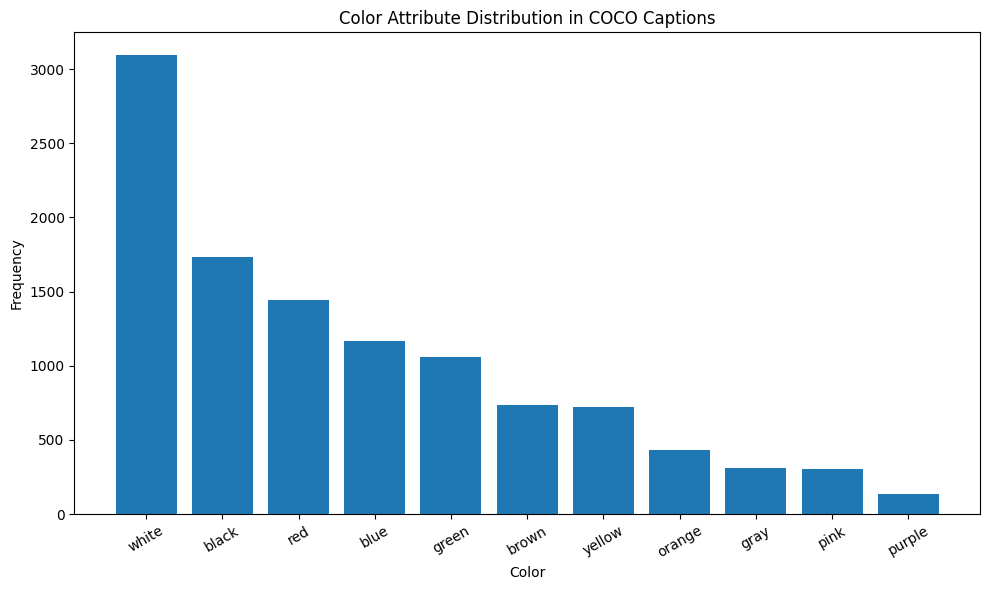

Color visualization saved successfully!
File: /content/drive/MyDrive/COCO_Project/statistics/color_attribute_distribution.png


In [27]:

# ==========================================
# 27. Color Distribution Visualization
# ==========================================

plt.figure(figsize=(10, 6))

plt.bar(
    color_df["Color"],
    color_df["Frequency"]
)

plt.title("Color Attribute Distribution in COCO Captions")
plt.xlabel("Color")
plt.ylabel("Frequency")

plt.xticks(rotation=30)
plt.tight_layout()

# Save visualization
color_graph_path = os.path.join(
    STATISTICS_DIR,
    "color_attribute_distribution.png"
)

plt.savefig(
    color_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

assert os.path.exists(color_graph_path), "Color visualization was not saved!"

print("Color visualization saved successfully!")
print("File:", color_graph_path)


In [28]:

# ==========================================
# 28. Shape and Dimension Attribute Analysis
# ==========================================

shape_words = {
    "round", "rounded", "circular", "square",
    "rectangular", "rectangle", "oval",
    "triangular", "triangle", "long", "short",
    "curved", "straight", "flat", "wide",
    "narrow", "small", "large", "thick", "thin"
}

shape_counts = Counter()

for caption in caption_texts:

    if not isinstance(caption, str) or not caption.strip():
        continue

    words = re.findall(r"\b[a-zA-Z]+\b", caption.lower())

    for word in words:
        if word in shape_words:
            shape_counts[word] += 1

# Create DataFrame
shape_df = pd.DataFrame(
    shape_counts.most_common(),
    columns=["Shape Attribute", "Frequency"]
)

# Calculate percentages
total_shape_mentions = shape_df["Frequency"].sum()

shape_df["Percentage"] = (
    shape_df["Frequency"] / total_shape_mentions
) * 100

print("SHAPE AND DIMENSION ATTRIBUTE DISTRIBUTION")
print("------------------------------------------")
print("Total attribute mentions:", total_shape_mentions)

display(shape_df)

# Save results
shape_path = os.path.join(
    STATISTICS_DIR,
    "shape_attribute_distribution.csv"
)

shape_df.to_csv(
    shape_path,
    index=False,
    encoding="utf-8"
)

assert os.path.exists(shape_path), "Shape statistics were not saved!"

print("\nShape statistics saved successfully!")
print("File:", shape_path)


SHAPE AND DIMENSION ATTRIBUTE DISTRIBUTION
------------------------------------------
Total attribute mentions: 4452


,Shape Attribute,Frequency,Percentage
0,large,2052,46.091644
1,small,1675,37.623540
2,long,279,6.266846
3,square,70,1.572327
4,flat,59,1.325247
5,wide,55,1.235400
6,round,54,1.212938
7,short,49,1.100629
8,narrow,48,1.078167
9,circular,25,0.561545



Shape statistics saved successfully!
File: /content/drive/MyDrive/COCO_Project/statistics/shape_attribute_distribution.csv


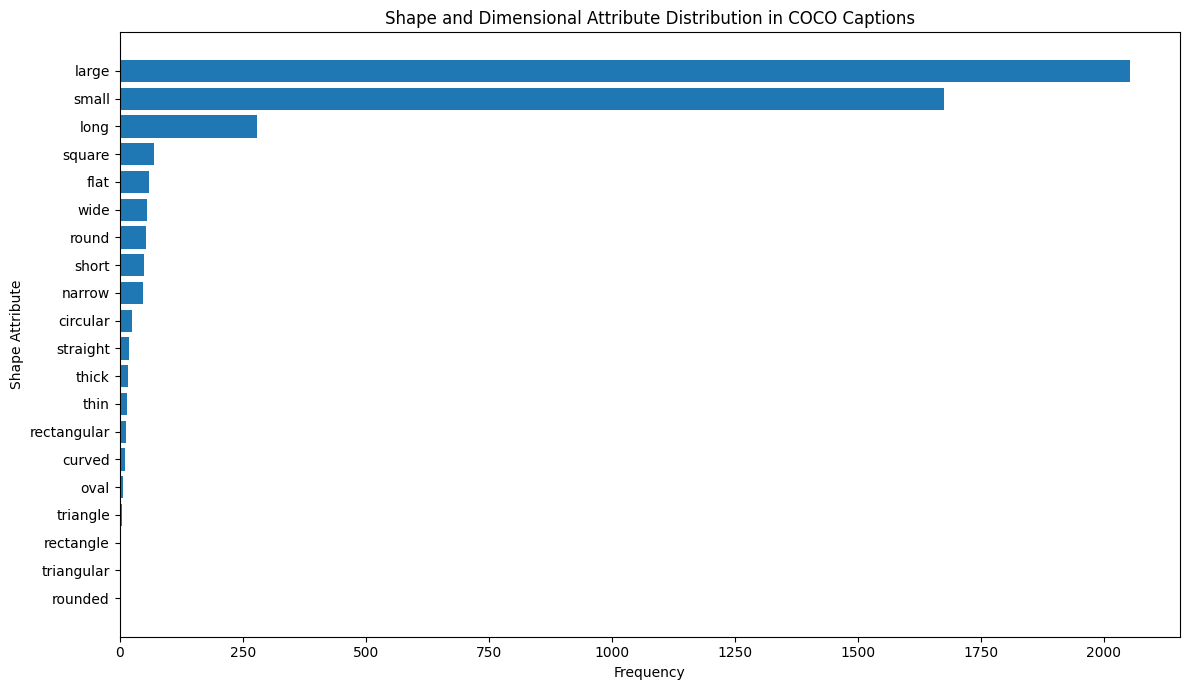

Shape visualization saved successfully!
File: /content/drive/MyDrive/COCO_Project/statistics/shape_attribute_distribution.png


In [29]:

# ==========================================
# 30. Shape Attribute Visualization
# ==========================================

plt.figure(figsize=(12, 7))

plt.barh(
    shape_df["Shape Attribute"][::-1],
    shape_df["Frequency"][::-1]
)

plt.title("Shape and Dimensional Attribute Distribution in COCO Captions")
plt.xlabel("Frequency")
plt.ylabel("Shape Attribute")

plt.tight_layout()

# Save visualization
shape_graph_path = os.path.join(
    STATISTICS_DIR,
    "shape_attribute_distribution.png"
)

plt.savefig(
    shape_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

assert os.path.exists(shape_graph_path), "Shape visualization was not saved!"

print("Shape visualization saved successfully!")
print("File:", shape_graph_path)


In [30]:

# ==========================================
# 31. Indoor and Outdoor Context Analysis
# ==========================================

indoor_words = {
    "indoor", "inside", "interior", "room", "bedroom",
    "bathroom", "kitchen", "living", "office", "classroom",
    "restaurant", "house", "home", "building", "hallway",
    "apartment", "hotel", "store", "shop"
}

outdoor_words = {
    "outdoor", "outside", "exterior", "street", "road",
    "sidewalk", "park", "garden", "beach", "field",
    "forest", "mountain", "sky", "grass", "stadium",
    "playground", "parking", "highway", "bridge", "yard"
}

context_counts = Counter()

for caption in caption_texts:

    if not isinstance(caption, str) or not caption.strip():
        continue

    words = set(re.findall(r"\b[a-zA-Z]+\b", caption.lower()))

    has_indoor = bool(words & indoor_words)
    has_outdoor = bool(words & outdoor_words)

    if has_indoor and has_outdoor:
        context_counts["Mixed"] += 1
    elif has_indoor:
        context_counts["Indoor"] += 1
    elif has_outdoor:
        context_counts["Outdoor"] += 1
    else:
        context_counts["Unspecified"] += 1

context_df = pd.DataFrame(
    context_counts.items(),
    columns=["Context", "Caption Count"]
)

total_captions = context_df["Caption Count"].sum()

context_df["Percentage"] = (
    context_df["Caption Count"] / total_captions * 100
)

context_df = context_df.sort_values(
    by="Caption Count",
    ascending=False
).reset_index(drop=True)

print("INDOOR / OUTDOOR CONTEXT DISTRIBUTION")
print("------------------------------------")
print("Total captions analyzed:", total_captions)

display(context_df)


INDOOR / OUTDOOR CONTEXT DISTRIBUTION
------------------------------------
Total captions analyzed: 50521


,Context,Caption Count,Percentage
0,Unspecified,34676,68.636804
1,Outdoor,9415,18.635815
2,Indoor,5976,11.828744
3,Mixed,454,0.898636


In [31]:

# ==========================================
# 32. Save Indoor / Outdoor Analysis
# ==========================================

context_path = os.path.join(
    STATISTICS_DIR,
    "indoor_outdoor_context_distribution.csv"
)

context_df.to_csv(context_path, index=False, encoding="utf-8")

assert os.path.exists(context_path), "Context analysis file was not saved!"

print("Indoor/Outdoor analysis saved successfully!")
print("File:", context_path)


Indoor/Outdoor analysis saved successfully!
File: /content/drive/MyDrive/COCO_Project/statistics/indoor_outdoor_context_distribution.csv


In [32]:

# ==========================================
# 33. Day / Night Context Analysis
# ==========================================

day_words = {
    "day", "daytime", "daylight", "sunny",
    "sunshine", "morning", "afternoon", "sunrise"
}

night_words = {
    "night", "nighttime", "midnight",
    "moon", "moonlight", "stars", "evening"
}

day_night_counts = Counter()

for caption in caption_texts:

    if not isinstance(caption, str) or not caption.strip():
        continue

    words = set(re.findall(r"\b[a-zA-Z]+\b", caption.lower()))

    has_day = bool(words & day_words)
    has_night = bool(words & night_words)

    if has_day and has_night:
        day_night_counts["Mixed"] += 1
    elif has_day:
        day_night_counts["Day"] += 1
    elif has_night:
        day_night_counts["Night"] += 1
    else:
        day_night_counts["Unspecified"] += 1

day_night_df = pd.DataFrame(
    day_night_counts.items(),
    columns=["Context", "Caption Count"]
)

total_captions = day_night_df["Caption Count"].sum()

day_night_df["Percentage"] = (
    day_night_df["Caption Count"] / total_captions * 100
)

day_night_df = day_night_df.sort_values(
    by="Caption Count",
    ascending=False
).reset_index(drop=True)

print("DAY / NIGHT CONTEXT DISTRIBUTION")
print("--------------------------------")
print("Total captions analyzed:", total_captions)

display(day_night_df)


DAY / NIGHT CONTEXT DISTRIBUTION
--------------------------------
Total captions analyzed: 50521


,Context,Caption Count,Percentage
0,Unspecified,49956,98.881653
1,Day,367,0.726431
2,Night,198,0.391916


In [ ]:
# ==========================================
# 35. Save Day / Night Context Analysis
# ==========================================

day_night_df.to_csv(
    os.path.join(STATISTICS_DIR, "day_night_context_distribution.csv"),
    index=False
)

print("Day/Night analysis saved successfully!")
print("File: day_night_context_distribution.csv")

Day/Night analysis saved successfully!
File: day_night_context_distribution.csv


In [ ]:
# ==========================================
# 36. Vocabulary Statistics JSON
# ==========================================

vocabulary_statistics = {
    "total_tokens": len(all_words),
    "unique_words": len(word_frequencies),
    "unique_words_without_stopwords": len(filtered_word_frequencies),
    "top_50_words": [
        {"word": word, "frequency": int(freq)}
        for word, freq in word_frequencies.most_common(50)
    ],
    "top_50_words_without_stopwords": [
        {"word": word, "frequency": int(freq)}
        for word, freq in filtered_word_frequencies.most_common(50)
    ]
}

vocabulary_json_path = os.path.join(
    STATISTICS_DIR, "vocabulary_statistics.json"
)

with open(vocabulary_json_path, "w", encoding="utf-8") as f:
    json.dump(vocabulary_statistics, f, indent=4)

print("Vocabulary statistics saved successfully!")
print("File: vocabulary_statistics.json")
print("Total tokens:", len(all_words))
print("Vocabulary size:", len(word_frequencies))

Vocabulary statistics saved successfully!
File: vocabulary_statistics.json
Total tokens: 529611
Vocabulary size: 9709


In [36]:
# ==========================================
# Diagnostic: Check image_object_counts
# ==========================================

print("Variable type:", type(image_object_counts))
print("First 10 values:", list(image_object_counts)[:10])

if isinstance(image_object_counts, dict):
    print("First 10 keys:", list(image_object_counts.keys())[:10])
    print("First 10 values:", list(image_object_counts.values())[:10])

Variable type: <class 'pandas.core.frame.DataFrame'>
First 10 values: ['image_id', 'object_count']


In [37]:

# ==========================================
# 37. Statistical Summary JSON
# ==========================================

object_counts_list = image_object_counts["object_count"].astype(int)

statistical_summary = {
    "dataset": {
        "name": "MS COCO 2017",

        "knowledge_base": {
            "source": "train2017",
            "images": 10000
        },

        "validation": {
            "source": "train2017",
            "images": 100
        },

        "test": {
            "source": "val2017",
            "images": 1000
        },

        "total_training_and_validation_images": 10100,
        "total_images_across_all_splits": 11100
    },

    "object_statistics": {
        "total_object_annotations": len(selected_instances),
        "number_of_categories": len(category_names),
        "most_frequent_category": category_df.iloc[0]["category"],
        "most_frequent_count": int(category_df.iloc[0]["object_count"]),
        "least_frequent_category": category_df.iloc[-1]["category"],
        "least_frequent_count": int(category_df.iloc[-1]["object_count"])
    },

    "objects_per_image": {
        "average": float(object_counts_list.mean()),
        "minimum": int(object_counts_list.min()),
        "maximum": int(object_counts_list.max()),
        "images_without_objects": int(
            (object_counts_list == 0).sum()
        )
    },

    "caption_statistics": {
        "total_captions": len(caption_texts),
        "minimum_length": int(min(caption_lengths)),
        "maximum_length": int(max(caption_lengths)),
        "average_length": float(np.mean(caption_lengths)),
        "median_length": float(np.median(caption_lengths))
    },

    "vocabulary_statistics": {
        "total_tokens": len(all_words),
        "unique_words": len(word_frequencies),
        "unique_words_without_stopwords": len(filtered_word_frequencies)
    },

    "diversity_analysis": {
        "color_attributes": color_df.to_dict(orient="records"),
        "shape_attributes": shape_df.to_dict(orient="records"),
        "indoor_outdoor_context": context_df.to_dict(orient="records"),
        "day_night_context": day_night_df.to_dict(orient="records")
    }
}

summary_path = os.path.join(
    STATISTICS_DIR, "statistical_summary.json"
)

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(statistical_summary, f, indent=4)

print("Statistical summary saved successfully!")
print("File: statistical_summary.json")
print("Training images: 10000")
print("Validation images: 100")
print("Test images: 1000")
print("Total project images: 11100")


Statistical summary saved successfully!
File: statistical_summary.json
Training images: 10000
Validation images: 100
Test images: 1000
Total project images: 11100


In [38]:
print("Type of list:", type(list))
print("Type of image_object_counts:", type(image_object_counts))
print("Type of np.mean:", type(np.mean))

Type of list: <class 'type'>
Type of image_object_counts: <class 'pandas.core.frame.DataFrame'>
Type of np.mean: <class 'numpy._ArrayFunctionDispatcher'>


In [39]:
print("Columns:", image_object_counts.columns.tolist())
print("\nFirst 5 rows:")
display(image_object_counts.head())
print("\nShape:", image_object_counts.shape)

Columns: ['image_id', 'object_count']

First 5 rows:


,image_id,object_count
0,458756,9
1,393224,6
2,131084,2
3,294925,7
4,98322,7



Shape: (10100, 2)


In [40]:

# ==========================================
# 39. Verify Statistical Summary JSON
# ==========================================

summary_path = os.path.join(
    STATISTICS_DIR, "statistical_summary.json"
)

assert os.path.exists(summary_path), "Summary file not found!"

with open(summary_path, "r", encoding="utf-8") as f:
    saved_summary = json.load(f)

print("Statistical summary verified successfully!")

print("\nDataset information:")
print(json.dumps(saved_summary["dataset"], indent=4))

print("\nObject statistics:")
print(json.dumps(saved_summary["object_statistics"], indent=4))

print("\nCaption statistics:")
print(json.dumps(saved_summary["caption_statistics"], indent=4))


Statistical summary verified successfully!

Dataset information:
{
    "name": "MS COCO 2017",
    "knowledge_base": {
        "source": "train2017",
        "images": 10000
    },
    "validation": {
        "source": "train2017",
        "images": 100
    },
    "test": {
        "source": "val2017",
        "images": 1000
    },
    "total_training_and_validation_images": 10100,
    "total_images_across_all_splits": 11100
}

Object statistics:
{
    "total_object_annotations": 72752,
    "number_of_categories": 80,
    "most_frequent_category": "person",
    "most_frequent_count": 22319,
    "least_frequent_category": "hair drier",
    "least_frequent_count": 18
}

Caption statistics:
{
    "total_captions": 50521,
    "minimum_length": 6,
    "maximum_length": 47,
    "average_length": 10.464875992161675,
    "median_length": 10.0
}


In [41]:
# ==========================================
# 40. Verify JSON Deliverables
# ==========================================

for filename in [
    "vocabulary_statistics.json",
    "statistical_summary.json"
]:
    file_path = os.path.join(STATISTICS_DIR, filename)

    with open(file_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    print(f"✓ {filename} — Valid JSON")

✓ vocabulary_statistics.json — Valid JSON
✓ statistical_summary.json — Valid JSON


In [42]:
# ==========================================
# 41. Rename Visualization Deliverables
# ==========================================

import shutil

visualization_files = {
    "top_50_object_classes.png": "top_50_objects.png",
    "objects_per_image_distribution.png": "objects_per_image.png",
    "caption_length_distribution.png": "caption_length.png"
}

for old_name, new_name in visualization_files.items():
    old_path = os.path.join(STATISTICS_DIR, old_name)
    new_path = os.path.join(STATISTICS_DIR, new_name)

    shutil.copy2(old_path, new_path)

    print(f"✓ Created: {new_name}")

print("\nAll required visualization files are ready!")

✓ Created: top_50_objects.png
✓ Created: objects_per_image.png
✓ Created: caption_length.png

All required visualization files are ready!


In [43]:
# ==========================================
# 42. Verify Required Deliverables
# ==========================================

required_files = [
    "top_50_objects.png",
    "objects_per_image.png",
    "caption_length.png",
    "vocabulary_statistics.json",
    "statistical_summary.json"
]

print("PERSON 2 — REQUIRED DELIVERABLES")
print("--------------------------------")

for filename in required_files:
    file_path = os.path.join(STATISTICS_DIR, filename)

    if os.path.exists(file_path):
        print(f"✓ {filename}")
    else:
        print(f"✗ MISSING: {filename}")

PERSON 2 — REQUIRED DELIVERABLES
--------------------------------
✓ top_50_objects.png
✓ objects_per_image.png
✓ caption_length.png
✓ vocabulary_statistics.json
✓ statistical_summary.json


In [52]:
# ==========================================
# 44. Generate Comprehensive Statistical Report
# ==========================================

import json
import os
import pandas as pd
import numpy as np

# Load POS distribution saved previously
pos_df = pd.read_csv(
    os.path.join(STATISTICS_DIR, "pos_distribution.csv")
)

# Calculate caption uniqueness
unique_captions = len(set(caption_texts))
repeated_captions = len(caption_texts) - unique_captions

# Build comprehensive report
comprehensive_report = {

   "1_dataset_overview": {
    "dataset_name": "MS COCO 2017",

    "knowledge_base": {
        "source": "train2017",
        "images": 10000
    },

    "validation": {
        "source": "train2017",
        "images": 100
    },

    "test": {
        "source": "val2017",
        "images": 1000
    },

    "total_training_and_validation_images": 10100,
    "total_images_across_all_splits": 11100,

    "total_object_annotations": len(selected_instances),
    "total_caption_annotations": len(selected_captions),
    "number_of_object_categories": len(category_names)
},

    "2_object_category_analysis": {
        "total_categories": len(category_names),
        "total_annotations": len(selected_instances),
        "average_annotations_per_category": float(category_df["object_count"].mean()),
        "most_frequent_category": {
            "name": str(category_df.iloc[0]["category"]),
            "count": int(category_df.iloc[0]["object_count"])
        },
        "least_frequent_category": {
            "name": str(category_df.iloc[-1]["category"]),
            "count": int(category_df.iloc[-1]["object_count"])
        },
        "all_category_frequencies": category_df.to_dict(orient="records"),
        "top_50_categories": category_df.head(50).to_dict(orient="records")
    },

    "3_objects_per_image_and_scene_complexity": {
        "total_images": len(image_object_counts),
        "average_objects_per_image": float(image_object_counts["object_count"].mean()),
        "minimum_objects_per_image": int(image_object_counts["object_count"].min()),
        "maximum_objects_per_image": int(image_object_counts["object_count"].max()),
        "images_without_object_annotations": int(
            (image_object_counts["object_count"] == 0).sum()
        ),
        "images_with_object_annotations": int(
            (image_object_counts["object_count"] > 0).sum()
        ),
        "scene_complexity_measure": "Number of annotated objects per image"
    },

    "4_caption_length_analysis": {
        "total_captions": len(caption_texts),
        "minimum_length_words": int(min(caption_lengths)),
        "maximum_length_words": int(max(caption_lengths)),
        "average_length_words": float(np.mean(caption_lengths)),
        "median_length_words": float(np.median(caption_lengths))
    },

    "5_vocabulary_analysis": {
        "total_word_tokens": len(all_words),
        "vocabulary_size": len(word_frequencies),
        "vocabulary_size_without_stopwords": len(filtered_word_frequencies),
        "top_50_words": [
            {"word": word, "frequency": int(freq)}
            for word, freq in word_frequencies.most_common(50)
        ],
        "top_50_words_without_stopwords": [
            {"word": word, "frequency": int(freq)}
            for word, freq in filtered_word_frequencies.most_common(50)
        ]
    },

    "6_part_of_speech_analysis": {
        "total_tagged_tokens": int(pos_df["Frequency"].sum()),
        "distribution": pos_df.to_dict(orient="records")
    },

    "7_caption_diversity_analysis": {
        "caption_uniqueness": {
            "total_captions": len(caption_texts),
            "unique_caption_texts": unique_captions,
            "repeated_caption_occurrences": repeated_captions,
            "unique_caption_percentage": float(
                unique_captions / len(caption_texts) * 100
            )
        },
        "color_attributes": color_df.to_dict(orient="records"),
        "shape_and_dimension_attributes": shape_df.to_dict(orient="records"),
        "indoor_outdoor_context": context_df.to_dict(orient="records"),
        "day_night_context": day_night_df.to_dict(orient="records")
    },

    "8_analysis_notes": {
        "object_distribution": "Object frequencies are based on COCO instance annotations.",
        "scene_complexity": "Measured using the number of annotated objects per image.",
        "caption_length": "Measured by counting whitespace-separated words.",
        "vocabulary": "Words were converted to lowercase and extracted using alphabetic regular expressions.",
        "stopword_analysis": "Stop-word removal was applied only for supplementary vocabulary analysis; original captions were not modified.",
        "pos_analysis": "Part-of-speech categories were obtained using NLTK tagging.",
        "diversity_analysis": "Color, shape, and context statistics are based on predefined keyword searches in captions, not direct visual measurements.",
        "day_night_analysis": "Captions without explicit day/night keywords are classified as unspecified.",
        "caption_uniqueness": "Uniqueness is based on exact caption-text comparison."
    }

}

# Save comprehensive report
summary_path = os.path.join(
    STATISTICS_DIR,
    "statistical_summary.json"
)

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(comprehensive_report, f, indent=4, ensure_ascii=False)

print("✓ Comprehensive statistical report generated!")
print("✓ Saved as:", summary_path)
print("✓ Report sections:", len(comprehensive_report))
print("✓ Object categories included:", len(category_df))
print("✓ POS categories included:", len(pos_df))
print("✓ Caption diversity analyses included.")

✓ Comprehensive statistical report generated!
✓ Saved as: /content/drive/MyDrive/COCO_Project/statistics/statistical_summary.json
✓ Report sections: 8
✓ Object categories included: 80
✓ POS categories included: 5
✓ Caption diversity analyses included.


In [45]:
# ==========================================
# 46. Investigate POS Tokenization Difference
# ==========================================

import re
import nltk
from nltk.tokenize import word_tokenize

regex_token_count = 0
nltk_token_count = 0
nltk_non_word_count = 0

for caption in caption_texts:

    # Original regular expression method
    regex_words = re.findall(
        r"\b[a-zA-Z]+\b",
        caption.lower()
    )

    # NLTK tokenization
    nltk_tokens = word_tokenize(caption.lower())

    nltk_words = [
        token for token in nltk_tokens
        if re.fullmatch(r"[a-zA-Z]+", token)
    ]

    regex_token_count += len(regex_words)
    nltk_token_count += len(nltk_tokens)
    nltk_non_word_count += len(nltk_tokens) - len(nltk_words)

print("POS TOKENIZATION INVESTIGATION")
print("--------------------------------")
print("Regex alphabetic tokens:", regex_token_count)
print("NLTK total tokens:", nltk_token_count)
print("NLTK alphabetic tokens:", nltk_token_count - nltk_non_word_count)
print("NLTK non-alphabetic tokens:", nltk_non_word_count)

print(
    "Difference between alphabetic token counts:",
    (nltk_token_count - nltk_non_word_count) - regex_token_count
)

print(
    "Original POS-tagged tokens:",
    int(pos_df["Frequency"].sum())
)

POS TOKENIZATION INVESTIGATION
--------------------------------
Regex alphabetic tokens: 529611
NLTK total tokens: 571635
NLTK alphabetic tokens: 527890
NLTK non-alphabetic tokens: 43745
Difference between alphabetic token counts: -1721
Original POS-tagged tokens: 571635


In [46]:
# ==========================================
# 47. Investigate Caption Counts Per Image
# ==========================================

caption_counts = Counter(
    ann["image_id"] for ann in selected_captions
)

caption_count_distribution = Counter(
    caption_counts.get(image_id, 0)
    for image_id in selected_all_ids
)

print("CAPTION COUNT INVESTIGATION")
print("--------------------------------")
print("Selected images:", len(selected_all_ids))
print("Total captions:", len(selected_captions))
print("Expected captions (5 per image):", len(selected_all_ids) * 5)

print("\nCaption counts per image:")
for count, number_of_images in sorted(caption_count_distribution.items()):
    print(f"{count} captions: {number_of_images} images")

print("\nImages with exactly 5 captions:",
      caption_count_distribution.get(5, 0))

CAPTION COUNT INVESTIGATION
--------------------------------
Selected images: 10100
Total captions: 50521
Expected captions (5 per image): 50500

Caption counts per image:
5 captions: 10079 images
6 captions: 21 images

Images with exactly 5 captions: 10079


In [47]:
# ==========================================
# 48. Identify Images with Six Captions
# ==========================================

images_with_six_captions = [
    image_id
    for image_id in selected_all_ids
    if caption_counts.get(image_id, 0) == 6
]

extra_caption_df = pd.DataFrame([
    {
        "image_id": image_id,
        "file_name": selected_ids_df.loc[
            selected_ids_df["image_id"] == image_id,
            "file_name"
        ].iloc[0],
        "caption_count": caption_counts[image_id]
    }
    for image_id in images_with_six_captions
])

display(extra_caption_df)

extra_caption_path = os.path.join(
    STATISTICS_DIR,
    "images_with_six_captions.csv"
)

extra_caption_df.to_csv(extra_caption_path, index=False)

print("Identified images:", len(extra_caption_df))
print("Investigation saved successfully!")

,image_id,file_name,caption_count
0,557447,000000557447.jpg,6
1,561789,000000561789.jpg,6
2,399213,000000399213.jpg,6
3,271875,000000271875.jpg,6
4,438701,000000438701.jpg,6
5,438926,000000438926.jpg,6
6,47640,000000047640.jpg,6
7,245243,000000245243.jpg,6
8,378149,000000378149.jpg,6
9,50601,000000050601.jpg,6


Identified images: 21
Investigation saved successfully!


In [48]:
# ==========================================
# 49. Investigate Images Without Objects
# ==========================================

images_without_objects = image_object_counts[
    image_object_counts["object_count"] == 0
]["image_id"].tolist()

no_object_df = pd.DataFrame([
    {
        "image_id": image_id,
        "file_name": selected_ids_df.loc[
            selected_ids_df["image_id"] == image_id,
            "file_name"
        ].iloc[0],
        "object_count": 0,
        "caption_count": caption_counts.get(image_id, 0)
    }
    for image_id in images_without_objects
])

print("IMAGES WITHOUT OBJECT ANNOTATIONS")
print("--------------------------------")
print("Total images:", len(no_object_df))
print("Images with captions:", (no_object_df["caption_count"] > 0).sum())
print("Images with 5 captions:", (no_object_df["caption_count"] == 5).sum())
print("Images with 6 captions:", (no_object_df["caption_count"] == 6).sum())
print("Images without captions:", (no_object_df["caption_count"] == 0).sum())

display(no_object_df.head(10))

no_object_path = os.path.join(
    STATISTICS_DIR,
    "images_without_object_annotations_investigation.csv"
)

no_object_df.to_csv(no_object_path, index=False)

print("\nInvestigation saved:", no_object_path)

IMAGES WITHOUT OBJECT ANNOTATIONS
--------------------------------
Total images: 104
Images with captions: 104
Images with 5 captions: 104
Images with 6 captions: 0
Images without captions: 0


,image_id,file_name,object_count,caption_count
0,262189,000000262189.jpg,0,5
1,328098,000000328098.jpg,0,5
2,524927,000000524927.jpg,0,5
3,427094,000000427094.jpg,0,5
4,558269,000000558269.jpg,0,5
5,198514,000000198514.jpg,0,5
6,68295,000000068295.jpg,0,5
7,35793,000000035793.jpg,0,5
8,3640,000000003640.jpg,0,5
9,429995,000000429995.jpg,0,5



Investigation saved: /content/drive/MyDrive/COCO_Project/statistics/images_without_object_annotations_investigation.csv


In [49]:
# ==========================================
# 50. Compare Average Objects Per Image
# ==========================================

total_images = len(image_object_counts)

images_with_objects_df = image_object_counts[
    image_object_counts["object_count"] > 0
]

average_all_images = image_object_counts["object_count"].mean()

average_images_with_objects = (
    images_with_objects_df["object_count"].mean()
)

print("OBJECTS PER IMAGE — COMPARISON")
print("--------------------------------")
print("Total images:", total_images)
print("Images with objects:", len(images_with_objects_df))
print("Images without objects:", total_images - len(images_with_objects_df))

print("\nAverage across all selected images:",
      round(average_all_images, 4))

print("Average among images with object annotations:",
      round(average_images_with_objects, 4))

OBJECTS PER IMAGE — COMPARISON
--------------------------------
Total images: 10100
Images with objects: 9996
Images without objects: 104

Average across all selected images: 7.2032
Average among images with object annotations: 7.2781


In [51]:
# ==========================================
# 51. Review and Improve Stop Words
# ==========================================

# Add frequently occurring words to the existing stop-word list
additional_stop_words = {
    "has",
    "other",
    "also",
    "one",
    "many"
}

stop_words.update(additional_stop_words)

# Recalculate filtered word frequencies
filtered_word_frequencies = Counter({
    word: frequency
    for word, frequency in word_frequencies.items()
    if word not in stop_words
})

print("UPDATED STOP-WORD LIST")
print("--------------------------------")
print("Total stop words:", len(stop_words))
print("Additional stop words:", sorted(additional_stop_words))

print("\nVerification of removed words:")
for word in sorted(additional_stop_words):
    print(f"{word}: {filtered_word_frequencies.get(word, 0)}")

print("\nUpdated vocabulary statistics:")
print("Total tokens:", len(all_words))
print("Original vocabulary size:", len(word_frequencies))
print("Filtered vocabulary size:", len(filtered_word_frequencies))

print("\nStop-word review completed successfully!")

UPDATED STOP-WORD LIST
--------------------------------
Total stop words: 57
Additional stop words: ['also', 'has', 'many', 'one', 'other']

Verification of removed words:
also: 0
has: 0
many: 0
one: 0
other: 0

Updated vocabulary statistics:
Total tokens: 529611
Original vocabulary size: 9709
Filtered vocabulary size: 9652

Stop-word review completed successfully!


In [53]:
# ==========================================
# 52. Improve Stop-Word List
# ==========================================

# Add additional common words to the existing stop-word list
additional_stop_words = {
    "have", "had", "others", "ones",
    "much", "very", "just",
    "there", "here", "their", "them",
    "who", "whom", "which", "whose"
}

stop_words.update(additional_stop_words)

# Recalculate filtered vocabulary
filtered_word_frequencies = Counter({
    word: frequency
    for word, frequency in word_frequencies.items()
    if word not in stop_words
})

# Generate updated top 50 descriptive words
filtered_vocabulary_df = pd.DataFrame(
    filtered_word_frequencies.most_common(50),
    columns=["word", "frequency"]
)

# Save updated CSV
filtered_vocabulary_df.to_csv(
    os.path.join(
        STATISTICS_DIR,
        "top_50_words_without_stopwords.csv"
    ),
    index=False
)

print("UPDATED STOP-WORD ANALYSIS")
print("--------------------------------")
print("Total stop words:", len(stop_words))
print("Newly added stop words:", len(additional_stop_words))
print("Original vocabulary size:", len(word_frequencies))
print("Filtered vocabulary size:", len(filtered_word_frequencies))

print("\nUpdated top 10 descriptive words:")
display(filtered_vocabulary_df.head(10))

UPDATED STOP-WORD ANALYSIS
--------------------------------
Total stop words: 69
Newly added stop words: 15
Original vocabulary size: 9709
Filtered vocabulary size: 9640

Updated top 10 descriptive words:


,word,frequency
0,man,6329
1,sitting,4542
2,two,4250
3,standing,3763
4,people,3606
5,next,3271
6,white,3093
7,woman,3076
8,street,2562
9,table,2554


In [54]:
# ==========================================
# 53. Update Comprehensive Statistical Report
# ==========================================

# Update vocabulary statistics
comprehensive_report["5_vocabulary_analysis"].update({
    "vocabulary_size": len(word_frequencies),
    "vocabulary_size_without_stopwords": len(filtered_word_frequencies),
    "stopword_list_size": len(stop_words),
    "number_of_words_removed": (
        len(word_frequencies) - len(filtered_word_frequencies)
    ),
    "top_50_words_without_stopwords": [
        {"word": word, "frequency": int(freq)}
        for word, freq in filtered_word_frequencies.most_common(50)
    ]
})

# Add tokenization investigation
comprehensive_report["6_part_of_speech_analysis"]["tokenization_investigation"] = {
    "regex_alphabetic_tokens": 529611,
    "nltk_total_tokens": 571635,
    "nltk_non_alphabetic_tokens": 43745,
    "nltk_alphabetic_tokens": 571635 - 43745,
    "difference_between_total_counts": 42024,
    "explanation": (
        "Regex and NLTK use different tokenization methods. "
        "NLTK includes punctuation and other non-alphabetic tokens, "
        "and may split certain expressions differently. "
        "Therefore, their total token counts are not directly comparable."
    )
}

comprehensive_report["6_part_of_speech_analysis"]["other_category_explanation"] = (
    "Other includes POS tags outside the noun, verb, adjective and adverb "
    "groups, such as determiners, prepositions, pronouns, conjunctions, "
    "punctuation and other grammatical tokens."
)

# Add caption-count investigation
comprehensive_report["4_caption_length_analysis"]["caption_count_investigation"] = {
    "images_with_five_captions": 10079,
    "images_with_six_captions": 21,
    "expected_if_every_image_had_five_captions": 50500,
    "actual_caption_count": 50521,
    "explanation": (
        "The 21 additional captions come from 21 images that have "
        "six caption annotations each. All other selected images "
        "have five captions."
    )
}

# Add scene complexity comparison
comprehensive_report["3_objects_per_image_and_scene_complexity"].update({
    "average_across_all_10100_images": 7.2032,
    "average_among_9996_images_with_objects": 7.2781,
    "denominator_explanation": (
        "The overall average includes all 10,100 selected images, "
        "including 104 images with zero object annotations. "
        "The second average considers only the 9,996 images "
        "with at least one object annotation."
    )
})

# Add investigation of images without object annotations
comprehensive_report["3_objects_per_image_and_scene_complexity"][
    "images_without_object_annotations_investigation"
] = {
    "number_of_images": 104,
    "images_with_captions": 104,
    "images_with_five_captions": 104,
    "images_with_six_captions": 0,
    "images_without_captions": 0,
    "decision": "All 104 images were retained in the dataset.",
    "explanation": (
        "All 104 images have five caption annotations but no associated "
        "object annotations in the selected instances annotation file. "
        "They are retained for caption analysis and counted as zero "
        "in the overall objects-per-image calculation."
    ),
    "investigation_file": "images_without_object_annotations_investigation.csv"
}

# Add investigation file for six-caption images
comprehensive_report["4_caption_length_analysis"][
    "six_caption_images_investigation_file"
] = "images_with_six_captions.csv"

# Update methodology notes
comprehensive_report["8_analysis_notes"].update({
    "tokenization_difference": (
        "Regex-based vocabulary counting and NLTK POS tokenization "
        "produce different totals because their tokenization rules differ."
    ),
    "caption_annotation_variation": (
        "The selected dataset contains 10,079 images with five captions "
        "and 21 images with six captions."
    ),
    "missing_object_annotations": (
        "104 images have five captions but zero object annotations. "
        "They were retained rather than automatically removed."
    ),
    "objects_per_image_average": (
        "The overall average uses 10,100 images; the conditional average "
        "uses only the 9,996 images with object annotations."
    ),
    "pos_other_category": (
        "Other groups all NLTK POS tags not classified as nouns, verbs, "
        "adjectives or adverbs."
    ),
    "stopword_list": (
        "The supplementary stop-word list was expanded to 69 words. "
        "Original captions remain unchanged."
    )
})

# Save updated report
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(
        comprehensive_report,
        f,
        indent=4,
        ensure_ascii=False
    )

print("✓ Comprehensive report updated successfully!")
print("✓ Tokenization investigation included.")
print("✓ Caption-count investigation included.")
print("✓ 104 images investigation included.")
print("✓ Both object averages included.")
print("✓ Updated vocabulary statistics included.")
print("✓ POS Other explanation included.")
print("\nSaved:", summary_path)

✓ Comprehensive report updated successfully!
✓ Tokenization investigation included.
✓ Caption-count investigation included.
✓ 104 images investigation included.
✓ Both object averages included.
✓ Updated vocabulary statistics included.
✓ POS Other explanation included.

Saved: /content/drive/MyDrive/COCO_Project/statistics/statistical_summary.json


In [56]:
# ==========================================
# 54. Update Vocabulary Statistics JSON
# ==========================================

# Rebuild the vocabulary statistics dictionary
vocabulary_statistics = {
    "total_tokens": len(all_words),

    "unique_words": len(word_frequencies),

    "unique_words_without_stopwords": len(filtered_word_frequencies),

    "number_of_stopwords": len(stop_words),

    "top_50_words": [
        {"word": word, "frequency": int(freq)}
        for word, freq in word_frequencies.most_common(50)
    ],

    "top_50_words_without_stopwords": [
        {"word": word, "frequency": int(freq)}
        for word, freq in filtered_word_frequencies.most_common(50)
    ]
}

# Save the updated JSON file
vocabulary_json_path = os.path.join(
    STATISTICS_DIR,
    "vocabulary_statistics.json"
)

with open(vocabulary_json_path, "w", encoding="utf-8") as f:
    json.dump(
        vocabulary_statistics,
        f,
        indent=4,
        ensure_ascii=False
    )

print("✓ vocabulary_statistics.json created and updated!")
print("Total tokens:", len(all_words))
print("Original vocabulary:", len(word_frequencies))
print("Filtered vocabulary:", len(filtered_word_frequencies))
print("Stop words:", len(stop_words))
print("Saved to:", vocabulary_json_path)

✓ vocabulary_statistics.json created and updated!
Total tokens: 529611
Original vocabulary: 9709
Filtered vocabulary: 9640
Stop words: 69
Saved to: /content/drive/MyDrive/COCO_Project/statistics/vocabulary_statistics.json


In [57]:
# ==========================================
# 55. Final JSON Validation
# ==========================================

# Load both saved files
with open(summary_path, "r", encoding="utf-8") as f:
    final_report = json.load(f)

with open(vocabulary_json_path, "r", encoding="utf-8") as f:
    final_vocabulary = json.load(f)

# Check report structure and investigation results
checks = {
    "Dataset overview": "1_dataset_overview" in final_report,
    "All 80 object categories": len(
        final_report["2_object_category_analysis"]["all_category_frequencies"]
    ) == 80,
    "Top 50 object categories": len(
        final_report["2_object_category_analysis"]["top_50_categories"]
    ) == 50,
    "Scene complexity": "3_objects_per_image_and_scene_complexity" in final_report,
    "Both object averages": (
        final_report["3_objects_per_image_and_scene_complexity"]
        ["average_across_all_10100_images"] == 7.2032
    ),
    "Caption analysis": "4_caption_length_analysis" in final_report,
    "Caption-count investigation": (
        final_report["4_caption_length_analysis"]
        ["caption_count_investigation"]["images_with_six_captions"] == 21
    ),
    "104 images investigation": (
        final_report["3_objects_per_image_and_scene_complexity"]
        ["images_without_object_annotations_investigation"]["number_of_images"] == 104
    ),
    "Vocabulary analysis": "5_vocabulary_analysis" in final_report,
    "POS analysis": len(
        final_report["6_part_of_speech_analysis"]["distribution"]
    ) == 5,
    "Caption diversity": "7_caption_diversity_analysis" in final_report,
    "Analysis notes": "8_analysis_notes" in final_report,
    "Updated vocabulary JSON": (
        final_vocabulary["unique_words_without_stopwords"] == 9640
    )
}

for name, result in checks.items():
    print(f"{'✓' if result else '✗'} {name}")

print("\nFinal result:",
      "ALL CHECKS PASSED" if all(checks.values()) else "SOME CHECKS FAILED")

✓ Dataset overview
✓ All 80 object categories
✓ Top 50 object categories
✓ Scene complexity
✓ Both object averages
✓ Caption analysis
✓ Caption-count investigation
✓ 104 images investigation
✓ Vocabulary analysis
✓ POS analysis
✓ Caption diversity
✓ Analysis notes
✓ Updated vocabulary JSON

Final result: ALL CHECKS PASSED


In [58]:
# ==========================================
# 56. Verify Required Deliverables
# ==========================================

required_files = [
    "top_50_objects.png",
    "objects_per_image.png",
    "caption_length.png",
    "vocabulary_statistics.json",
    "statistical_summary.json"
]

print("FINAL DELIVERABLES CHECK")
print("=" * 45)

for filename in required_files:
    filepath = os.path.join(STATISTICS_DIR, filename)

    if os.path.exists(filepath):
        size_kb = os.path.getsize(filepath) / 1024
        print(f"✓ {filename} ({size_kb:.2f} KB)")
    else:
        print(f"✗ MISSING: {filename}")

print("=" * 45)

FINAL DELIVERABLES CHECK
✓ top_50_objects.png (339.57 KB)
✓ objects_per_image.png (119.37 KB)
✓ caption_length.png (106.17 KB)
✓ vocabulary_statistics.json (7.97 KB)
✓ statistical_summary.json (44.48 KB)


In [ ]:
# ==========================================
# 58. Correct Stop-Word Field Names
# ==========================================

# Load statistical summary
with open(summary_path, "r", encoding="utf-8") as f:
    report = json.load(f)

# Load vocabulary statistics
with open(vocabulary_json_path, "r", encoding="utf-8") as f:
    vocabulary = json.load(f)

# Correct the field in the comprehensive report
vocabulary_section = report["5_vocabulary_analysis"]

old_value = vocabulary_section.pop(
    "number_of_stopwords_removed",
    len(stop_words)
)

vocabulary_section["unique_stopword_types_removed"] = old_value

# Add the correctly named field to vocabulary statistics
vocabulary["unique_stopword_types_removed"] = len(stop_words)

# Save both JSON files
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=4, ensure_ascii=False)

with open(vocabulary_json_path, "w", encoding="utf-8") as f:
    json.dump(vocabulary, f, indent=4, ensure_ascii=False)

# Verify
print("✓ Statistical summary updated.")
print("✓ Vocabulary statistics updated.")

print("\nVerification:")
print(
    "Statistical summary:",
    vocabulary_section["unique_stopword_types_removed"]
)
print(
    "Vocabulary statistics:",
    vocabulary["unique_stopword_types_removed"]
)

✓ Statistical summary updated.
✓ Vocabulary statistics updated.

Verification:
Statistical summary: 69
Vocabulary statistics: 69
